In [ ]:
!pip install -q kagglehub
import kagglehub, glob, os, shutil

path = kagglehub.dataset_download("sriramr/fruits-fresh-and-rotten-for-classification")
print("Descargado en:", path)

Using Colab cache for faster access to the 'fruits-fresh-and-rotten-for-classification' dataset.
Descargado en: /kaggle/input/fruits-fresh-and-rotten-for-classification


In [ ]:
dst = "/content/banana"
for split in ["train", "test"]:
    for cls in ["freshbanana", "rottenbanana"]:
        for src in glob.glob(f"{path}/**/{split}/{cls}", recursive=True):
            shutil.copytree(src, f"{dst}/{split}/{cls}", dirs_exist_ok=True)

total = 0
for root, dirs, files in os.walk(dst):
    if not dirs:
        print(root, "->", len(files))
        total += len(files)
print("TOTAL bananos:", total)

/content/banana/train/freshbanana -> 1581
/content/banana/train/rottenbanana -> 2224
/content/banana/test/freshbanana -> 381
/content/banana/test/rottenbanana -> 530
TOTAL bananos: 4716


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
shutil.make_archive("/content/drive/MyDrive/banana_dataset", "zip", "/content/banana")

Mounted at /content/drive


'/content/drive/MyDrive/banana_dataset.zip'

In [ ]:
!pip install -q imagehash scikit-learn
import imagehash, numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

# 1. Juntar train y test (sano = fresh, deteriorado = rotten)
rutas, etiquetas = [], []
for split in ["train", "test"]:
    for cls, etq in [("freshbanana", "sano"), ("rottenbanana", "deteriorado")]:
        for f in glob.glob(f"/content/banana/{split}/{cls}/*"):
            rutas.append(f); etiquetas.append(etq)
print("Imágenes juntas:", len(rutas))

# 2. Huella visual (hash) de cada imagen
hashes, ok_rutas, ok_etq = [], [], []
for r, e in zip(rutas, etiquetas):
    try:
        h = imagehash.phash(Image.open(r).convert("RGB"))
        hashes.append(h.hash.flatten()); ok_rutas.append(r); ok_etq.append(e)
    except Exception:
        print("No se pudo leer:", r)
H = np.array(hashes).astype(np.float32)

# 3. Distancia entre huellas: 0 = idénticas, número bajo = casi iguales
dist = 64 - (H @ H.T + (1 - H) @ (1 - H).T)
UMBRAL = 4

mantener, quitado, conflicto = [], np.zeros(len(ok_rutas), bool), set()
for i in range(len(ok_rutas)):
    if quitado[i]:
        continue
    mantener.append(i)
    for j in np.where(dist[i] <= UMBRAL)[0]:
        if j > i:
            quitado[j] = True
            if ok_etq[j] != ok_etq[i]:
                conflicto.add(i)          # parecidas pero con etiqueta distinta
mantener = [i for i in mantener if i not in conflicto]
print("Repetidas quitadas:", int(quitado.sum()), "| con etiqueta en conflicto:", len(conflicto))
print("Quedan:", len(mantener))

# 4. Dividir 70/15/15 manteniendo la proporción sano/deteriorado
X = [ok_rutas[i] for i in mantener]; y = [ok_etq[i] for i in mantener]
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)

for nombre, xs, ys in [("train", X_tr, y_tr), ("val", X_va, y_va), ("test", X_te, y_te)]:
    for f, e in zip(xs, ys):
        os.makedirs(f"/content/data/{nombre}/{e}", exist_ok=True)
        shutil.copy(f, f"/content/data/{nombre}/{e}/{os.path.basename(f)}")
    print(nombre, "->", len(xs), "| sanos:", ys.count("sano"), "| deteriorados:", ys.count("deteriorado"))

Imágenes juntas: 4716
Repetidas quitadas: 675 | con etiqueta en conflicto: 14
Quedan: 4027
train -> 2818 | sanos: 1151 | deteriorados: 1667
val -> 604 | sanos: 247 | deteriorados: 357
test -> 605 | sanos: 247 | deteriorados: 358


In [ ]:
shutil.make_archive("/content/drive/MyDrive/banana_split_70_15_15", "zip", "/content/data")

'/content/drive/MyDrive/banana_split_70_15_15.zip'

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Hardware activo: Tesla T4
Mounted at /content/drive
train | sano        -> 1151
train | deteriorado -> 1667
val   | sano        -> 247
val   | deteriorado -> 357
test  | sano        -> 247
test  | deteriorado -> 358
TOTAL: 4027


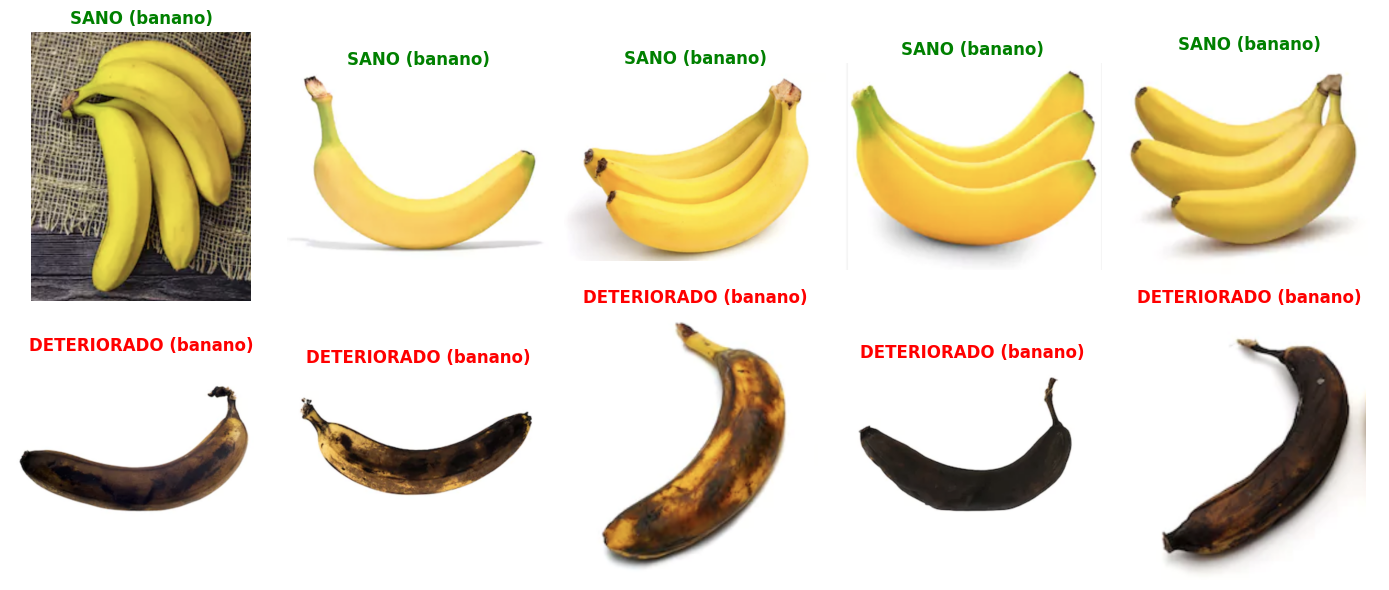

In [ ]:
# ==============================================================================
# CELDA 1: CONFIGURACIÓN Y CARGA DEL DATASET DE BANANO (train / val / test)
# ==============================================================================
!pip install -q ultralytics imagehash gradio opencv-python-headless

import os, shutil, random, zipfile
import numpy as np
import pandas as pd
import cv2
import imagehash
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import torchvision.transforms.functional as TF
from sklearn.metrics import f1_score, confusion_matrix
from ultralytics import YOLOWorld, SAM
import gradio as gr

# 1. Semilla y GPU
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Hardware activo:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

# 2. Cargar la división 70/15/15 desde Drive (solo si no está ya en esta sesión)
from google.colab import drive
drive.mount('/content/drive')
ZIP = '/content/drive/MyDrive/banana_split_DEFINITIVO.zip'
if not os.path.exists('data/train'):
    with zipfile.ZipFile(ZIP) as z:
        z.extractall('data')


total = 0
for parte in ['train', 'val', 'test']:
    for clase in ['sano', 'deteriorado']:
        n = len(os.listdir(f'data/{parte}/{clase}'))
        total += n
        print(f'{parte:5s} | {clase:11s} -> {n}')
print('TOTAL:', total)

# 4. Cuadrícula de verificación visual (muestras de entrenamiento)
n_muestras = 5
fig, axes = plt.subplots(2, n_muestras, figsize=(14, 6))
for fila, (clase, color) in enumerate([('sano', 'green'), ('deteriorado', 'red')]):
    archivos = sorted(os.listdir(f'data/train/{clase}'))[:n_muestras]
    for i, nombre in enumerate(archivos):
        axes[fila, i].imshow(Image.open(f'data/train/{clase}/{nombre}'))
        axes[fila, i].set_title(clase.upper() + ' (banano)', color=color, fontweight='bold')
        axes[fila, i].axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# CELDA 2: LECTURA DE LA PARTICIÓN ANTI-FUGA (ya limpia y dividida 70/15/15)
# ==============================================================================

registros = []
for parte in ['train', 'val', 'test']:
    for nombre_clase, etiqueta in [('sano', 0), ('deteriorado', 1)]:
        carpeta = f'data/{parte}/{nombre_clase}'
        for archivo in sorted(os.listdir(carpeta)):
            registros.append({
                'ruta': os.path.join(carpeta, archivo),
                'etiqueta': etiqueta,
                'clase': nombre_clase,
                'parte': parte
            })

df = pd.DataFrame(registros)
train_df = df[df['parte'] == 'train'].reset_index(drop=True)
val_df   = df[df['parte'] == 'val'].reset_index(drop=True)
test_df  = df[df['parte'] == 'test'].reset_index(drop=True)

print(f'Particiones -> Train: {len(train_df)} | Val: {len(val_df)} | Test (aislado): {len(test_df)}')
print(df.groupby(['parte', 'clase']).size())

# Verificación: ningún archivo debe estar en dos particiones a la vez
nombres = {p: set(os.path.basename(r) for r in df[df['parte'] == p]['ruta']) for p in ['train', 'val', 'test']}
print('Compartidos train-val:', len(nombres['train'] & nombres['val']),
      '| train-test:', len(nombres['train'] & nombres['test']),
      '| val-test:', len(nombres['val'] & nombres['test']))

Particiones -> Train: 2818 | Val: 604 | Test (aislado): 605
parte  clase      
test   deteriorado     358
       sano            247
train  deteriorado    1667
       sano           1151
val    deteriorado     357
       sano            247
dtype: int64
Compartidos train-val: 0 | train-test: 0 | val-test: 0


In [ ]:
shutil.copy('/content/drive/MyDrive/banana_split_70_15_15.zip',
            '/content/drive/MyDrive/banana_split_FINAL.zip')

manifiesto = df.copy()
manifiesto['archivo'] = manifiesto['ruta'].apply(os.path.basename)
manifiesto[['archivo', 'clase', 'parte']].to_csv('/content/drive/MyDrive/manifiesto_division_banano.csv', index=False)
print(manifiesto.groupby(['parte', 'clase']).size())

shutil.copy('/content/drive/MyDrive/clasificador_banano.pth',
            '/content/drive/MyDrive/clasificador_banano_reparto4024.pth')
print('Copias guardadas.')

parte  clase      
test   deteriorado     358
       sano            247
train  deteriorado    1667
       sano           1151
val    deteriorado     357
       sano            247
dtype: int64
Copias guardadas.


In [ ]:
# ==============================================================================
# CELDA 3: PREPARACIÓN COHERENTE Y COMPARACIÓN DE MODELOS (ETAPAS 3 Y 4) - BANANO
# ==============================================================================
from sklearn.metrics import precision_score, recall_score

class DatasetBananoCoherente(Dataset):
    def __init__(self, dataframe, tamano=224, aumentar=False):
        self.df = dataframe.reset_index(drop=True)
        self.tamano = tamano
        self.aumentar = aumentar
        self.normalizar = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    def _generar_mascara(self, img_pil):
        # Quita el fondo claro (blanco/gris muy claro). Si queda muy poco banano, usa la imagen completa.
        img_np = np.array(img_pil)
        gris = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
        _, mascara = cv2.threshold(gris, 240, 255, cv2.THRESH_BINARY_INV)
        if np.sum(mascara > 0) < 0.10 * mascara.size:
            mascara = np.ones_like(gris) * 255
        return Image.fromarray(mascara)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        fila = self.df.iloc[idx]
        img = Image.open(fila['ruta']).convert('RGB')
        mascara = self._generar_mascara(img)
        etiqueta = int(fila['etiqueta'])

        img = TF.resize(img, (self.tamano, self.tamano))
        mascara = TF.resize(mascara, (self.tamano, self.tamano), interpolation=TF.InterpolationMode.NEAREST)

        if self.aumentar:
            if random.random() > 0.5:
                img, mascara = TF.hflip(img), TF.hflip(mascara)
            if random.random() > 0.5:
                img, mascara = TF.vflip(img), TF.vflip(mascara)
            angulo = random.uniform(-25, 25)
            img, mascara = TF.rotate(img, angulo), TF.rotate(mascara, angulo)
            img = transforms.ColorJitter(brightness=0.15, contrast=0.15)(img)

        img_t = TF.to_tensor(img)
        mascara_t = (TF.to_tensor(mascara) > 0.5).float()
        assert mascara_t.sum() > 0, 'Máscara vacía detectada'

        img_enmascarada = self.normalizar(img_t * mascara_t)
        return img_enmascarada, torch.tensor(etiqueta, dtype=torch.long)

resultados = []   # aquí se guarda la tabla comparativa para el informe

def entrenar_y_evaluar(nombre_exp, aumentar=False, ajuste_fino=False, epocas=8):
    # Misma semilla en cada ejecución: así arrancan igual y la comparación es justa
    torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    random.seed(SEED); np.random.seed(SEED)

    loader_train = DataLoader(DatasetBananoCoherente(train_df, aumentar=aumentar),
                              batch_size=32, shuffle=True, num_workers=2)
    loader_val = DataLoader(DatasetBananoCoherente(val_df, aumentar=False),
                            batch_size=32, shuffle=False, num_workers=2)

    modelo = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    for param in modelo.features.parameters():
        param.requires_grad = False
    if ajuste_fino:
        for param in modelo.features[-2:].parameters():
            param.requires_grad = True

    modelo.classifier[1] = nn.Linear(modelo.last_channel, 2)
    modelo = modelo.to(device)

    optimizador = torch.optim.Adam(filter(lambda p: p.requires_grad, modelo.parameters()), lr=1e-4)
    funcion_perdida = nn.CrossEntropyLoss()

    for ep in range(epocas):
        modelo.train()
        for x, y in loader_train:
            x, y = x.to(device), y.to(device)
            optimizador.zero_grad()
            perdida = funcion_perdida(modelo(x), y)
            perdida.backward()
            optimizador.step()

    # Evaluación en VALIDACIÓN (el test queda aislado hasta el final)
    modelo.eval()
    probs, reales = [], []
    with torch.no_grad():
        for x, y in loader_val:
            p = torch.softmax(modelo(x.to(device)), dim=1)[:, 1].cpu().numpy()
            probs.extend(p); reales.extend(y.numpy())
    probs, reales = np.array(probs), np.array(reales)

    # Se mide con los dos umbrales para separar el efecto del umbral del efecto del entrenamiento
    for umbral in [0.50, 0.40]:
        pred = (probs >= umbral).astype(int)
        matriz = confusion_matrix(reales, pred, labels=[0, 1])
        fila = {
            'Ejecución': nombre_exp, 'Umbral': umbral,
            'Precisión': round(precision_score(reales, pred, zero_division=0), 4),
            'Recall': round(recall_score(reales, pred, zero_division=0), 4),
            'F1': round(f1_score(reales, pred, zero_division=0), 4),
            'FN (deteriorado->sano)': int(matriz[1, 0]),
            'FP (sano->deteriorado)': int(matriz[0, 1]),
        }
        resultados.append(fila)
        print(f"[{nombre_exp} | umbral {umbral:.2f}] F1: {fila['F1']:.4f} | "
              f"Recall: {fila['Recall']:.4f} | FN (error crítico): {fila['FN (deteriorado->sano)']} | "
              f"FP: {fila['FP (sano->deteriorado)']}")
    return modelo

modelo_baseline = entrenar_y_evaluar('Ejecución 1: Baseline (sin aumento, capas congeladas)',
                                     aumentar=False, ajuste_fino=False)
modelo_final = entrenar_y_evaluar('Ejecución 2: Controlada (aumento + fine-tuning)',
                                  aumentar=True, ajuste_fino=True)
model_final = modelo_final

print('\n=== TABLA COMPARATIVA (validación) ===')
print(pd.DataFrame(resultados).to_string(index=False))

torch.save(modelo_final.state_dict(), 'clasificador_banano.pth')
shutil.copy('clasificador_banano.pth', '/content/drive/MyDrive/clasificador_banano.pth')
print('Modelo guardado (local y en Drive).')

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 120MB/s]


[Ejecución 1: Baseline (sin aumento, capas congeladas) | umbral 0.50] F1: 0.9986 | Recall: 1.0000 | FN (error crítico): 0 | FP: 1
[Ejecución 1: Baseline (sin aumento, capas congeladas) | umbral 0.40] F1: 0.9958 | Recall: 1.0000 | FN (error crítico): 0 | FP: 3
[Ejecución 2: Controlada (aumento + fine-tuning) | umbral 0.50] F1: 1.0000 | Recall: 1.0000 | FN (error crítico): 0 | FP: 0
[Ejecución 2: Controlada (aumento + fine-tuning) | umbral 0.40] F1: 1.0000 | Recall: 1.0000 | FN (error crítico): 0 | FP: 0

=== TABLA COMPARATIVA (validación) ===
                                            Ejecución  Umbral  Precisión  Recall     F1  FN (deteriorado->sano)  FP (sano->deteriorado)
Ejecución 1: Baseline (sin aumento, capas congeladas)     0.5     0.9972     1.0 0.9986                       0                       1
Ejecución 1: Baseline (sin aumento, capas congeladas)     0.4     0.9917     1.0 0.9958                       0                       3
      Ejecución 2: Controlada (aumento + fin

In [ ]:
pd.DataFrame(resultados).to_csv('/content/drive/MyDrive/resultados_validacion_banano.csv', index=False)

NameError: name 'pd' is not defined

In [ ]:
# ==============================================================================
# CELDA 4: DETECCIÓN + SEGMENTACIÓN + GRADIO (BANANO)
# ==============================================================================
gr.close_all()   # cierra interfaces anteriores para no repetir el enlace

# Si la sesión se reinició y se perdió el modelo, se carga desde Drive
if 'modelo_final' not in globals():
    modelo_final = models.mobilenet_v2(weights=None)
    modelo_final.classifier[1] = nn.Linear(modelo_final.last_channel, 2)
    modelo_final.load_state_dict(torch.load('/content/drive/MyDrive/clasificador_banano.pth', map_location=device))
    modelo_final = modelo_final.to(device)
modelo_final.eval()

detector = YOLOWorld('yolov8s-worldv2.pt')
detector.set_classes(['banana', 'yellow banana', 'brown rotten banana'])
segmentador = SAM('mobile_sam.pt')

UMBRAL_INCIERTO = 0.70   # por debajo de esta confianza se marca el banano con "?"

def dibujar_etiqueta(img, texto, x, y, color):
    # Escribe el texto con fondo negro y sin salirse de la imagen
    fuente, escala, grosor = cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2
    (tw, th), base = cv2.getTextSize(texto, fuente, escala, grosor)
    x = int(min(max(0, x), max(0, img.shape[1] - tw - 6)))
    y = int(min(max(th + 6, y), img.shape[0] - base - 2))
    cv2.rectangle(img, (x, y - th - 6), (x + tw + 6, y + base), (0, 0, 0), -1)
    cv2.putText(img, texto, (x + 3, y - 3), fuente, escala, color, grosor)

def analizar_lote_bananos(imagen_entrada, umbral_deteccion=0.10, umbral_deterioro=0.40, iou_nms=0.45):
    if imagen_entrada is None:
        return None, 'Por favor sube una imagen con 3 o más bananos.'

    img_rgb = np.array(imagen_entrada.convert('RGB'))
    alto, ancho, _ = img_rgb.shape
    resultado_visual = img_rgb.copy()

    # 1. Detectar cada banano (iou_nms: qué tanto se pueden traslapar dos cajas sin borrar una)
    res_det = detector.predict(img_rgb, conf=umbral_deteccion, iou=iou_nms, agnostic_nms=True, verbose=False)[0]
    if res_det.boxes is None or len(res_det.boxes) == 0:
        return Image.fromarray(resultado_visual), 'No se detectaron bananos. Baja el umbral de detección o revisa la foto.'

    cajas = res_det.boxes.xyxy.cpu().numpy()

    # 2. Máscara de cada banano con MobileSAM
    res_sam = segmentador.predict(img_rgb, bboxes=cajas, verbose=False)[0]
    if res_sam.masks is None:
        return Image.fromarray(resultado_visual), 'No se pudieron generar máscaras.'
    mascaras = res_sam.masks.data.cpu().numpy()

    normalizar = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    total, sanos, deteriorados, inciertos = 0, 0, 0, 0
    lista_detalles = []

    for masc_cruda, caja in zip(mascaras, cajas):
        masc_bin = cv2.resize(masc_cruda.astype(np.uint8), (ancho, alto)) > 0

        # Descartar ruido diminuto (< 1.5% del área de la foto)
        if masc_bin.sum() < 0.015 * (alto * ancho):
            continue

        x1, y1, x2, y2 = map(int, caja)
        banano_aislado = img_rgb.copy()
        banano_aislado[~masc_bin] = 0
        recorte = banano_aislado[max(0, y1):min(alto, y2), max(0, x1):min(ancho, x2)]
        if recorte.size == 0:
            continue

        total += 1

        # 3. Clasificar el estado con MobileNetV2
        recorte_pil = Image.fromarray(recorte).resize((224, 224))
        tensor_entrada = normalizar(TF.to_tensor(recorte_pil)).unsqueeze(0).to(device)
        with torch.no_grad():
            prob_deterioro = torch.softmax(modelo_final(tensor_entrada), dim=1)[0, 1].item()

        if prob_deterioro >= umbral_deterioro:
            deteriorados += 1
            estado, confianza, color = 'DETERIORADO', prob_deterioro, (220, 40, 40)
        else:
            sanos += 1
            estado, confianza, color = 'SANO', 1.0 - prob_deterioro, (40, 190, 60)

        incierto = confianza < UMBRAL_INCIERTO
        if incierto:
            inciertos += 1

        overlay_color = np.array(color)
        resultado_visual[masc_bin] = (resultado_visual[masc_bin] * 0.55 + overlay_color * 0.45).astype(np.uint8)
        contornos, _ = cv2.findContours(masc_bin.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(resultado_visual, contornos, -1, color, 2)

        etiqueta = f'ID#{total} {estado} ({confianza:.2f})' + (' ?' if incierto else '')
        ys, xs = np.where(masc_bin)
        dibujar_etiqueta(resultado_visual, etiqueta, int(xs.mean()) - 70, int(ys.mean()), color)   # <- etiqueta nueva
        lista_detalles.append(etiqueta)

    if total == 0:
        return Image.fromarray(resultado_visual), 'Se detectaron objetos, pero ninguno tenía tamaño suficiente.'

    resumen = (
        f'RESUMEN DEL LOTE DE BANANOS:\n'
        f'• Total de bananos detectados: {total}\n'
        f'• Bananos sanos: {sanos}\n'
        f'• Bananos deteriorados: {deteriorados}\n'
        f'• Con confianza baja (marcados con ?): {inciertos}\n\n'
        f'Detalle por ejemplar:\n' + '\n'.join(lista_detalles)
    )
    return Image.fromarray(resultado_visual), resumen

interfaz = gr.Interface(
    fn=analizar_lote_bananos,
    inputs=[
        gr.Image(type='pil', label='Sube una foto con 3 o más bananos'),
        gr.Slider(0.01, 0.90, value=0.10, step=0.01, label='Umbral de detección (sensibilidad para hallar bananos)'),
        gr.Slider(0.10, 0.90, value=0.40, step=0.05, label='Umbral de deterioro (sensibilidad para marcar daño)'),
        gr.Slider(0.30, 0.95, value=0.45, step=0.05, label='Umbral IoU del filtro NMS (más alto = conserva cajas que se traslapan)')
    ],
    outputs=[
        gr.Image(type='pil', label='Segmentación individual y clasificación'),
        gr.Textbox(label='Conteo y diagnóstico del lote', lines=10)
    ],
    title='Control de Calidad de Banano — Segmentación por instancia',
    description='YOLO-World + MobileSAM (segmentación) y MobileNetV2 (estado: sano o deteriorado). Inspección solo visual.'
)

interfaz.launch(share=True)


requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 37 packages in 872ms
Prepared 2 packages in 4.29s
Installed 2 packages in 2ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@7ffa84b3bfa40c42ecc1c77147a855e69cb2dd40)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 5.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



100%|███████████████████████████████████████| 338M/338M [00:24<00:00, 14.5MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://62add34e02a79dbbd4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ==============================================================================
# CELDA 5: EVALUACIÓN FINAL EN TEST (usar UNA sola vez, con el modelo y umbral ya decididos)
# ==============================================================================
from sklearn.metrics import classification_report

loader_test = DataLoader(DatasetBananoCoherente(test_df, aumentar=False),
                         batch_size=32, shuffle=False, num_workers=2)
modelo_final.eval()
probs, reales = [], []
with torch.no_grad():
    for x, y in loader_test:
        p = torch.softmax(modelo_final(x.to(device)), dim=1)[:, 1].cpu().numpy()
        probs.extend(p); reales.extend(y.numpy())
probs, reales = np.array(probs), np.array(reales)

UMBRAL_FINAL = 0.40
pred = (probs >= UMBRAL_FINAL).astype(int)
print('Matriz de confusión (filas = real, columnas = predicho; 0 sano, 1 deteriorado):')
print(confusion_matrix(reales, pred, labels=[0, 1]))
print(classification_report(reales, pred, target_names=['sano', 'deteriorado'], digits=4))

errores = test_df[pred != reales].copy()
errores['prob_deterioro'] = probs[pred != reales]
print('Errores en test:', len(errores))
print(errores[['ruta', 'clase', 'prob_deterioro']].to_string())

Matriz de confusión (filas = real, columnas = predicho; 0 sano, 1 deteriorado):
[[247   0]
 [  0 358]]
              precision    recall  f1-score   support

        sano     1.0000    1.0000    1.0000       247
 deteriorado     1.0000    1.0000    1.0000       358

    accuracy                         1.0000       605
   macro avg     1.0000    1.0000    1.0000       605
weighted avg     1.0000    1.0000    1.0000       605

Errores en test: 0
Empty DataFrame
Columns: [ruta, clase, prob_deterioro]
Index: []


/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


     palabras  conf  iou_nms  detectados
tres_palabras  0.05     0.45           3
tres_palabras  0.05     0.70           4
tres_palabras  0.05     0.90           6
tres_palabras  0.10     0.45           2
tres_palabras  0.10     0.70           2
tres_palabras  0.10     0.90           3
single_banana  0.05     0.45           4
single_banana  0.05     0.70           6
single_banana  0.05     0.90           7
single_banana  0.10     0.45           3
single_banana  0.10     0.70           4
single_banana  0.10     0.90           5
Configuración que más detectó: 7 -> single_banana_conf0.05_iou0.9.png


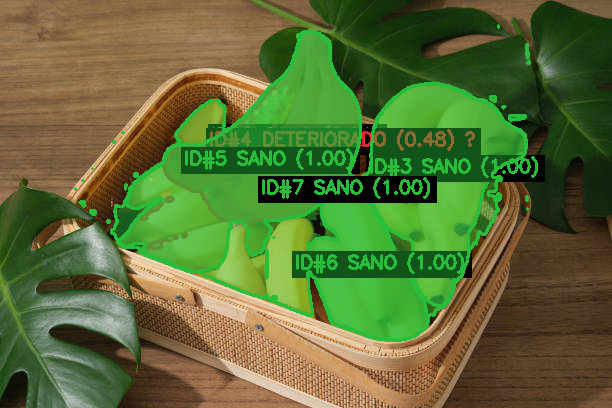

In [ ]:
import re
from IPython.display import display

RUTA_FOTO = '/content/fotos/canasta.jpg'   # <- pega aquí la ruta de tu foto
foto = Image.open(RUTA_FOTO).convert('RGB')
os.makedirs('/content/resultados_nms', exist_ok=True)

PALABRAS_ORIGINAL = ['banana', 'yellow banana', 'brown rotten banana']
opciones_palabras = {'tres_palabras': PALABRAS_ORIGINAL, 'single_banana': ['single banana']}

filas = []
for nombre_p, palabras in opciones_palabras.items():
    detector.set_classes(palabras)
    for conf in [0.05, 0.10]:
        for iou in [0.45, 0.70, 0.90]:
            img_res, resumen = analizar_lote_bananos(foto, umbral_deteccion=conf, umbral_deterioro=0.40, iou_nms=iou)
            m = re.search(r'Total de bananos detectados: (\d+)', resumen)
            total = int(m.group(1)) if m else 0
            archivo = f'{nombre_p}_conf{conf}_iou{iou}.png'
            img_res.save(f'/content/resultados_nms/{archivo}')
            filas.append({'palabras': nombre_p, 'conf': conf, 'iou_nms': iou, 'detectados': total, 'archivo': archivo})

detector.set_classes(PALABRAS_ORIGINAL)   # deja el detector como estaba
tabla = pd.DataFrame(filas)
print(tabla[['palabras', 'conf', 'iou_nms', 'detectados']].to_string(index=False))
tabla.to_csv('/content/drive/MyDrive/experimento_deteccion.csv', index=False)

mas = tabla.sort_values('detectados', ascending=False).iloc[0]
print('Configuración que más detectó:', mas['detectados'], '->', mas['archivo'])
display(Image.open(f"/content/resultados_nms/{mas['archivo']}"))

In [ ]:
rows = []
for parte in ['train', 'val', 'test']:
    for clase in ['sano', 'deteriorado']:
        for f in sorted(os.listdir(f'data/{parte}/{clase}')):
            rows.append({'archivo': f, 'clase': clase, 'parte': parte})
manifiesto = pd.DataFrame(rows)
print(manifiesto.groupby(['parte', 'clase']).size()); print('Total:', len(manifiesto))

if len(manifiesto) == 4027:
    shutil.make_archive('/content/drive/MyDrive/banana_split_DEFINITIVO', 'zip', 'data')
    manifiesto.to_csv('/content/drive/MyDrive/manifiesto_DEFINITIVO.csv', index=False)
    shutil.copy('/content/drive/MyDrive/clasificador_banano.pth',
                '/content/drive/MyDrive/clasificador_banano_DEFINITIVO.pth')
    print('DEFINITIVO guardado.')
else:
    print('El total no es 4027: NO se guardó nada. Avísame.')

parte  clase      
test   deteriorado     358
       sano            247
train  deteriorado    1667
       sano           1151
val    deteriorado     357
       sano            247
dtype: int64
Total: 4027
DEFINITIVO guardado.


In [ ]:
import time
import numpy as np
from PIL import Image

img = Image.open('/content/fotos/canasta.jpg')
analizar_lote_bananos(img)          # calentamiento: la primera llamada es más lenta

tiempos = []
for _ in range(10):
    t0 = time.perf_counter()
    analizar_lote_bananos(img)
    tiempos.append(time.perf_counter() - t0)

print(f'Promedio: {np.mean(tiempos):.2f} s | mín: {min(tiempos):.2f} s | máx: {max(tiempos):.2f} s')

In [ ]:
import torch
modelo_final.load_state_dict(torch.load('/content/drive/MyDrive/clasificador_banano_DEFINITIVO.pth', map_location=device))
modelo_final.eval()
print('Modelo DEFINITIVO cargado. Hardware:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

Modelo DEFINITIVO cargado. Hardware: Tesla T4


In [ ]:
import re, time, glob, os
import numpy as np, pandas as pd
from PIL import Image

CARPETA = '/content/drive/MyDrive/fotos_banano'
SALIDA  = '/content/drive/MyDrive/resultados_fotos'
os.makedirs(SALIDA, exist_ok=True)

UMBRAL_DETERIORO = 0.40
CONFIGS = [(d, n) for d in (0.02, 0.10) for n in (0.45, 0.70)]   # (detección, NMS)

rutas = sorted(glob.glob(f'{CARPETA}/*.jpeg') + glob.glob(f'{CARPETA}/*.jpg'))
print(len(rutas), 'fotos encontradas')

def leer(etiqueta, texto):
    r = re.search(etiqueta + r': (\d+)', texto)
    return int(r.group(1)) if r else 0

analizar_lote_bananos(Image.open(rutas[0]).convert('RGB'), umbral_deteccion=0.02,
                      umbral_deterioro=UMBRAL_DETERIORO, iou_nms=0.45)   # calentamiento

filas = []
for umb, nms in CONFIGS:
    for ruta in rutas:
        nombre = os.path.basename(ruta)
        m = re.match(r'F(\d+)_S(\d+)_D(\d+)(?:_X(\d+))?', nombre)
        if not m:
            print('Nombre no válido:', nombre); continue
        n_foto, s, d, x = int(m[1]), int(m[2]), int(m[3]), int(m[4] or 0)
        if n_foto <= 3:          # F01-F03 son de ajuste
            continue
        img = Image.open(ruta).convert('RGB')
        t0 = time.perf_counter()
        salida, resumen = analizar_lote_bananos(img, umbral_deteccion=umb,
                                                umbral_deterioro=UMBRAL_DETERIORO, iou_nms=nms)
        seg = time.perf_counter() - t0
        salida.save(f'{SALIDA}/{os.path.splitext(nombre)[0]}_det{umb}_nms{nms}.png')
        filas.append({'det': umb, 'nms': nms, 'foto': nombre, 'real_total': s + d + x,
                      'real_sanos': s, 'real_det': d, 'real_dudosos': x,
                      'det_total': leer('Total de bananos detectados', resumen),
                      'det_sanos': leer('Bananos sanos', resumen),
                      'det_det': leer('Bananos deteriorados', resumen),
                      'segundos': round(seg, 2)})

tabla = pd.DataFrame(filas)
tabla['error_total'] = tabla['det_total'] - tabla['real_total']
tabla.to_csv(f'{SALIDA}/conteo_fotos.csv', index=False)
print(tabla.to_string(index=False))
for (umb, nms), g in tabla.groupby(['det', 'nms']):
    print(f"\n== Detección {umb} | NMS {nms} ==  fotos: {len(g)} | conteo exacto: {(g['error_total']==0).sum()} de {len(g)}"
          f" | error absoluto medio: {g['error_total'].abs().mean():.2f}"
          f" | de más: {(g['error_total']>0).sum()} | de menos: {(g['error_total']<0).sum()}"
          f" | tiempo prom: {g['segundos'].mean():.2f} s (mín {g['segundos'].min():.2f}, máx {g['segundos'].max():.2f})")

20 fotos encontradas
 det  nms           foto  real_total  real_sanos  real_det  real_dudosos  det_total  det_sanos  det_det  segundos  error_total
0.02 0.45 F04_S2_D1.jpeg           3           2         1             0          4          2        2      0.75            1
0.02 0.45 F05_S2_D2.jpeg           4           2         2             0          5          2        3      0.85            1
0.02 0.45 F06_S2_D1.jpeg           3           2         1             0          4          2        2      1.46            1
0.02 0.45 F07_S2_D2.jpeg           4           2         2             0          3          2        1      0.59           -1
0.02 0.45 F08_S2_D2.jpeg           4           2         2             0          5          0        5      1.30            1
0.02 0.45 F09_S2_D3.jpeg           5           2         3             0          6          2        4      1.09            1
0.02 0.45 F10_S2_D3.jpeg           5           2         3             0          6       